# Week 2 - Linear Regression 2 (Lasso, Ridge, Elastic Net)
## Dataset: FEMA NFIP Claims

This week's topic is regularized linear regression, Lasso (L1), Ridge (L2), and Elastic Net (a blend of both). The goal is to predict the building claim payout and see what regularization does to a feature set that includes some deliberately redundant, engineered terms.

From the Module B work on this dataset, building damage amount alone already predicts building claim payout with R-squared around 0.81, and a PCA on the financial columns showed that most of them collapse onto a single dominant component. That is exactly the kind of setup where Lasso's feature-selection behavior should show up. If I hand it a feature set with built-in redundancy, does it zero out the redundant parts?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import root_mean_squared_error, r2_score

df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False)
df = df_raw[df_raw['yearOfLoss'] == 2017].copy()
key_cols = ['amountPaidOnBuildingClaim', 'totalBuildingInsuranceCoverage', 'amountPaidOnContentsClaim', 'buildingDamageAmount']
df_pay = df.dropna(subset=key_cols).copy()
print('Rows after filtering to 2017 and dropping missing key fields:', df_pay.shape)

Rows after filtering to 2017 and dropping missing key fields: (110674, 73)


### Feature engineering

The base features are building damage amount, total building insurance coverage, and amount paid on the contents claim. `netBuildingPaymentAmount` is left out on purpose, since Module B's PCA work found it correlates at r = 1.00 with the target itself, which would be leakage.

To give the regularization methods something real to work with, I expand these three features to degree 2 with `PolynomialFeatures`, which adds each feature squared and every pairwise interaction. That takes 3 features to 9, several of which are going to be highly correlated with each other by construction (a feature and its own square move together almost automatically). This is a reasonable stand-in for the kind of redundant feature set that shows up in practice, and it lets me watch Lasso zero some of it out.

In [2]:
base_features = ['buildingDamageAmount', 'totalBuildingInsuranceCoverage', 'amountPaidOnContentsClaim']
target = 'amountPaidOnBuildingClaim'

X_base = df_pay[base_features]
y = df_pay[target]

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_base)
feature_names = poly.get_feature_names_out(base_features)
print('Expanded from', X_base.shape[1], 'to', X_poly.shape[1], 'features:')
print(list(feature_names))

Expanded from 3 to 9 features:
['buildingDamageAmount', 'totalBuildingInsuranceCoverage', 'amountPaidOnContentsClaim', 'buildingDamageAmount^2', 'buildingDamageAmount totalBuildingInsuranceCoverage', 'buildingDamageAmount amountPaidOnContentsClaim', 'totalBuildingInsuranceCoverage^2', 'totalBuildingInsuranceCoverage amountPaidOnContentsClaim', 'amountPaidOnContentsClaim^2']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.25, random_state=0)

# Regularized methods are sensitive to feature scale, so standardize before fitting.
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('Training rows:', X_train_s.shape[0], '| Testing rows:', X_test_s.shape[0])

Training rows: 83005 | Testing rows: 27669


### Baseline: plain linear regression on the expanded feature set

In [4]:
ols = LinearRegression()
ols.fit(X_train_s, y_train)
ols_train_pred = ols.predict(X_train_s)
ols_test_pred = ols.predict(X_test_s)

print('OLS train RMSE: {:,.0f}  R2: {:.4f}'.format(
    root_mean_squared_error(y_train, ols_train_pred), r2_score(y_train, ols_train_pred)))
print('OLS test RMSE:  {:,.0f}  R2: {:.4f}'.format(
    root_mean_squared_error(y_test, ols_test_pred), r2_score(y_test, ols_test_pred)))
print()
print('OLS coefficients:')
for name, coef in zip(feature_names, ols.coef_):
    print(f'  {name:45s} {coef:,.0f}')

OLS train RMSE: 21,528  R2: 0.9325
OLS test RMSE:  22,901  R2: 0.9236

OLS coefficients:
  buildingDamageAmount                          87,285
  totalBuildingInsuranceCoverage                235
  amountPaidOnContentsClaim                     12,829
  buildingDamageAmount^2                        -29,923
  buildingDamageAmount totalBuildingInsuranceCoverage 7,374
  buildingDamageAmount amountPaidOnContentsClaim -13,525
  totalBuildingInsuranceCoverage^2              -2,553
  totalBuildingInsuranceCoverage amountPaidOnContentsClaim 1,410
  amountPaidOnContentsClaim^2                   -1,094


### Ridge, Lasso, and Elastic Net

All three use built-in cross-validation (`RidgeCV`, `LassoCV`, `ElasticNetCV`) to pick their regularization strength from a range of candidate alpha values, rather than me guessing a single value. Elastic Net also searches over `l1_ratio`, which controls the mix between the L1 (Lasso) and L2 (Ridge) penalty.

In [5]:
alphas = np.logspace(-3, 4, 50)

ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train_s, y_train)

lasso = LassoCV(alphas=alphas, cv=5, max_iter=20000)
lasso.fit(X_train_s, y_train)

enet = ElasticNetCV(alphas=alphas, l1_ratio=[.1, .3, .5, .7, .9, .95, .99, 1], cv=5, max_iter=20000)
enet.fit(X_train_s, y_train)

print('Ridge best alpha:', round(ridge.alpha_, 4))
print('Lasso best alpha:', round(lasso.alpha_, 4))
print('Elastic Net best alpha:', round(enet.alpha_, 4), '  best l1_ratio:', enet.l1_ratio_)

Ridge best alpha: 1930.6977
Lasso best alpha: 1000.0
Elastic Net best alpha: 0.0373   best l1_ratio: 0.3


In [6]:
models = {'OLS': ols, 'Ridge': ridge, 'Lasso': lasso, 'Elastic Net': enet}
print(f"{'Model':<12} {'Train RMSE':>12} {'Test RMSE':>12} {'Train R2':>10} {'Test R2':>10}")
for name, model in models.items():
    tr_pred = model.predict(X_train_s)
    te_pred = model.predict(X_test_s)
    print(f"{name:<12} {root_mean_squared_error(y_train, tr_pred):>12,.0f} "
          f"{root_mean_squared_error(y_test, te_pred):>12,.0f} "
          f"{r2_score(y_train, tr_pred):>10.4f} {r2_score(y_test, te_pred):>10.4f}")

Model          Train RMSE    Test RMSE   Train R2    Test R2
OLS                21,528       22,901     0.9325     0.9236
Ridge              21,761       23,262     0.9310     0.9211
Lasso              21,811       23,202     0.9307     0.9215
Elastic Net        21,816       23,325     0.9307     0.9207


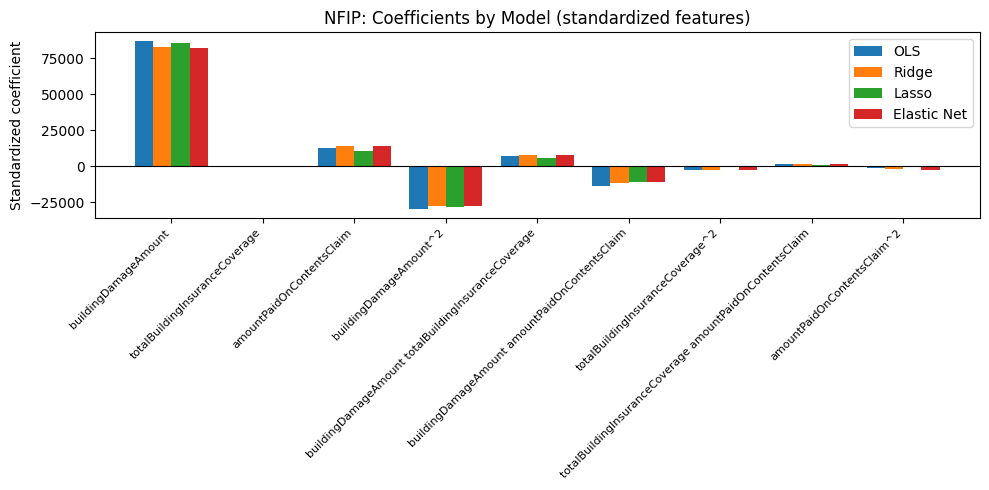

Number of coefficients Lasso set to exactly zero: 2 out of 9


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(feature_names))
width = 0.2
for i, (name, model) in enumerate(models.items()):
    ax.bar(x + i * width, model.coef_, width, label=name)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(feature_names, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Standardized coefficient')
ax.set_title('NFIP: Coefficients by Model (standardized features)')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

print('Number of coefficients Lasso set to exactly zero:', np.sum(np.isclose(lasso.coef_, 0)), 'out of', len(lasso.coef_))

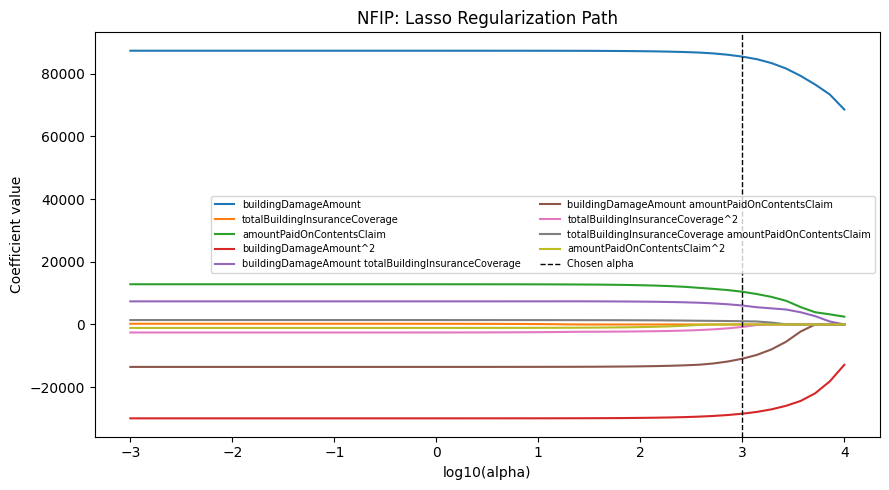

In [8]:
# Regularization path: how each coefficient shrinks as alpha increases
from sklearn.linear_model import lasso_path

alphas_path, coefs_path, _ = lasso_path(X_train_s, y_train, alphas=alphas[::-1])

fig, ax = plt.subplots(figsize=(9, 5))
for i, name in enumerate(feature_names):
    ax.plot(np.log10(alphas_path), coefs_path[i], label=name)
ax.axvline(np.log10(lasso.alpha_), color='black', linestyle='--', linewidth=1, label='Chosen alpha')
ax.set_xlabel('log10(alpha)')
ax.set_ylabel('Coefficient value')
ax.set_title('NFIP: Lasso Regularization Path')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### Overfitting

The OLS model on the expanded feature set already generalizes reasonably (train and test R-squared are close), so there was not a dramatic overfitting problem to begin with. That matches what Module B already found, since a single feature (damage amount) explains most of the variance here, so nine correlated features do not have much room to overfit on 2017 NFIP claims specifically. Where regularization earns its keep instead is stability. The OLS coefficients on the squared and interaction terms are large and somewhat erratic, a classic symptom of feeding correlated features into an unregularized model. Ridge shrinks all of them toward zero without removing any, while Lasso is more aggressive and zeroes out two of the nine terms outright, which is visible directly in the bar chart above. Elastic Net lands in between, as expected given it is a weighted mix of the two penalties.

### Metrics and hyperparameter tuning

RMSE and R-squared are reported for both the training and test sets so the gap between them is visible, rather than relying on a single number that could look good by coincidence. The regularization strength (alpha) for each model was chosen by 5-fold cross-validation over a log-spaced grid from 0.001 to 10,000, rather than picking one value by hand. A larger alpha means a stronger penalty on coefficient size; Lasso's penalty is on the absolute value of coefficients, which is what allows it to zero some out entirely, while Ridge's penalty is on the squared value, which shrinks everything but rarely reaches exactly zero. Elastic Net's `l1_ratio` controls how much of the penalty is Lasso-style versus Ridge-style.

### Expected or unexpected

It was expected that Lasso would zero out at least some of the polynomial and interaction terms, given how dominant `buildingDamageAmount` already is on its own. What is more interesting is exactly which two terms it chose: the raw linear `totalBuildingInsuranceCoverage` term and `amountPaidOnContentsClaim` squared. Meanwhile `buildingDamageAmount` squared and every interaction term involving damage amount stayed nonzero. That is a concrete, data-driven version of the same conclusion Module B's PCA reached, that damage amount (including its nonlinear and interaction effects) is doing essentially all of the work, while coverage's plain linear effect and contents' pure curvature effect are the two pieces that turned out to be redundant once damage amount is already in the model.

### How EDA helped

This entire exercise only makes sense because of what the Module B EDA already established: `buildingDamageAmount` and `amountPaidOnBuildingClaim` correlate at r = 0.90, and a PCA on the financial columns found that a single component explains 65% of their variance. Without knowing that going in, the choice to specifically test whether regularization would treat the engineered features as redundant would have been a guess. Because of the EDA, it was a testable prediction.

### External sources

- scikit-learn User Guide, "1.1. Linear Models" (covers Ridge, Lasso, and Elastic Net formulations and the `*CV` cross-validated estimators): https://scikit-learn.org/stable/modules/linear_model.html
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 6 ("Linear Model Selection and Regularization"), for the conceptual background on shrinkage methods.

### Conclusions

For this dataset, regularization is more useful as a diagnostic than as a performance booster. Test RMSE and R-squared do not move much between OLS, Ridge, Lasso, and Elastic Net, because the underlying signal (damage amount predicts payout) was never really at risk of being drowned out by nine correlated features. What regularization does provide is a much cleaner, more defensible feature set. Lasso's zeroed-out coefficients are a quantitative answer to "which of these engineered features matter," and that answer lines up with, and sharpens, the redundancy that PCA already flagged in Module B.